# 01 · EDA — Store Sales
Source: Kaggle "Store Sales – Time Series Forecasting", loaded into SQLite.
Goals: (1) total daily sales trend, (2) top 10 product families by sales.


In [1]:
import sqlite3
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB_PATH = ROOT / "data" / "store_sales.db"   # change if your DB has another name
TABLE = "train"
DOCS = ROOT / "docs"
DOCS.mkdir(exist_ok=True)

print(DB_PATH, DB_PATH.exists())

c:\Users\DHRUV MEWARA\Downloads\demand-forecast\data\store_sales.db True


In [2]:
with sqlite3.connect(DB_PATH) as conn:
    print(pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", conn))
    print(pd.read_sql(f"SELECT * FROM {TABLE} LIMIT 5", conn))

              name
0            train
1           stores
2     transactions
3              oil
4  holidays_events
   id        date  store_nbr      family  sales  onpromotion
0   0  2013-01-01          1  AUTOMOTIVE    0.0            0
1   1  2013-01-01          1   BABY CARE    0.0            0
2   2  2013-01-01          1      BEAUTY    0.0            0
3   3  2013-01-01          1   BEVERAGES    0.0            0
4   4  2013-01-01          1       BOOKS    0.0            0


In [3]:
with sqlite3.connect(DB_PATH) as conn:
    daily = pd.read_sql(f"""
        SELECT date, SUM(sales) AS total_sales
        FROM {TABLE}
        GROUP BY date
        ORDER BY date
    """, conn, parse_dates=["date"])

print(daily.shape)
daily.head()

(1684, 2)


,date,total_sales
0,2013-01-01,2511.618999
1,2013-01-02,496092.417944
2,2013-01-03,361461.231124
3,2013-01-04,354459.677093
4,2013-01-05,477350.121229


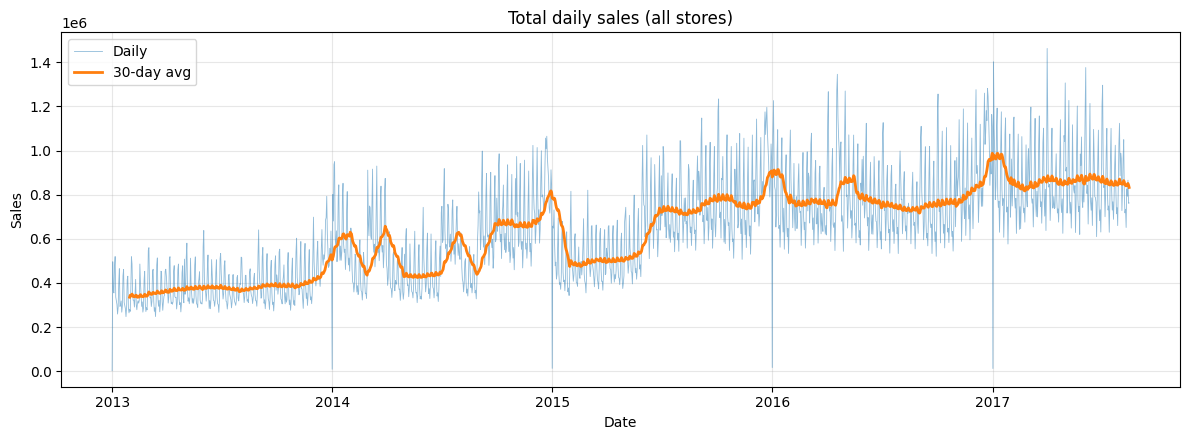

In [4]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(daily["date"], daily["total_sales"], linewidth=0.6, alpha=0.5, label="Daily")
ax.plot(daily["date"], daily["total_sales"].rolling(30).mean(), linewidth=2, label="30-day avg")
ax.set_title("Total daily sales (all stores)")
ax.set_xlabel("Date")
ax.set_ylabel("Sales")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(DOCS / "daily_sales_trend.png", dpi=150)
plt.show()

In [5]:
with sqlite3.connect(DB_PATH) as conn:
    top10 = pd.read_sql(f"""
        SELECT family, SUM(sales) AS total_sales
        FROM {TABLE}
        GROUP BY family
        ORDER BY total_sales DESC
        LIMIT 10
    """, conn)
top10

,family,total_sales
0,GROCERY I,3.434627e+08
1,BEVERAGES,2.169545e+08
2,PRODUCE,1.227047e+08
3,CLEANING,9.752129e+07
4,DAIRY,6.448771e+07
5,BREAD/BAKERY,4.213395e+07
6,POULTRY,3.187600e+07
7,MEATS,3.108647e+07
8,PERSONAL CARE,2.459205e+07
9,DELI,2.411032e+07


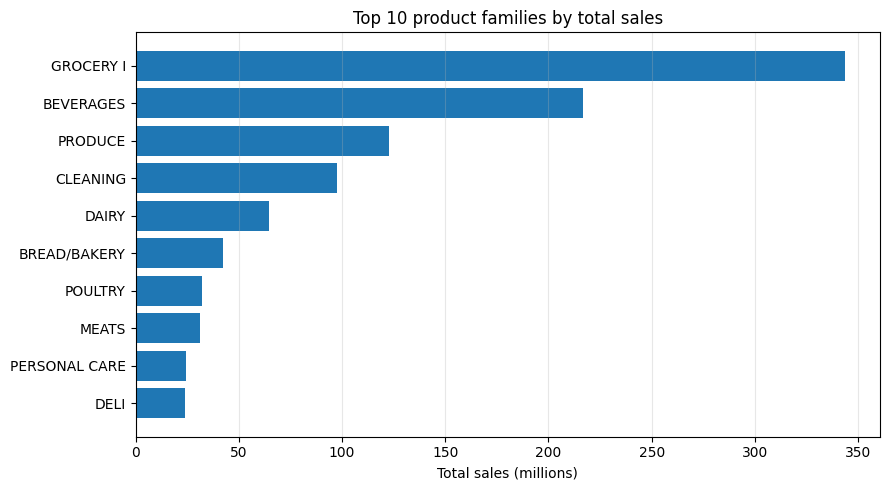

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
plot_df = top10.sort_values("total_sales")
ax.barh(plot_df["family"], plot_df["total_sales"] / 1e6)
ax.set_title("Top 10 product families by total sales")
ax.set_xlabel("Total sales (millions)")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(DOCS / "top10_families.png", dpi=150)
plt.show()

## Observations
- **Trend:** total daily sales rise steadily from 2013 to 2017 (see the 30-day avg line).
- **Spikes / dips:** sales drop to almost zero on 1 Jan each year (stores closed) and peak in late December.
- **Top families:** GROCERY I is the largest family by a wide margin, followed by BEVERAGES, PRODUCE and CLEANING. The top few families make up most of the sales, so they matter most for forecasting.